In [23]:
from pathlib import Path

import pandas as pd

# the data is in eda/old_ag_news_csv/; this works whether the notebook starts in eda/ or in the project root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
DATA = ROOT / 'eda' / 'old_ag_news_csv'

train_df = pd.read_csv(DATA / 'train.csv', names=['class', 'title', 'description'])
test_df = pd.read_csv(DATA / 'test.csv', names=['class', 'title', 'description'])
train_df.head()

,class,title,description
0,3,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
1,3,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...
2,3,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...
3,3,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...
4,3,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco..."


### Klasy


| ID | Nazwa |
| -------- | -------- |
| 1 | World |
| 2 | Sports |
| 3 | Business |
| 4 | Sci/Tech |

In [24]:
classes = {
    1: 'World', 
    2: 'Sports', 
    3: 'Business', 
    4: 'Sci/Tech'
}

### Dystrybucja klas na zbiorze treningowym

In [25]:
train_df['class'].value_counts()

class
3    30000
4    30000
2    30000
1    30000
Name: count, dtype: int64

### Dystrybucja klas na zbiorze testowym

In [26]:
test_df['class'].value_counts()

class
3    1900
4    1900
2    1900
1    1900
Name: count, dtype: int64

In [27]:
import re

import matplotlib.pyplot as plt
from wordcloud import STOPWORDS, WordCloud


def clean_text(text):
    text = re.sub(r'[^A-Za-z\s]', '', text) 

    text = text.lower()

    stopwords = set(STOPWORDS)
    return ' '.join(word for word in text.split() if word not in stopwords)


def generate_wordcloud(text):

    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  
    plt.show()

## Wszystkie klasy razem

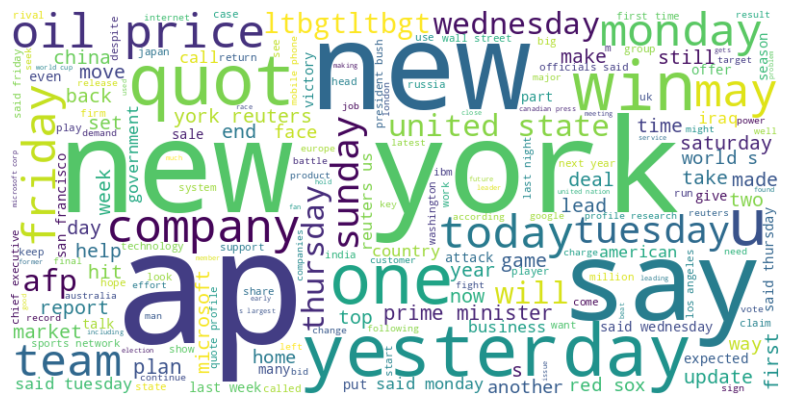

In [28]:
text_titles = clean_text(' '.join(train_df['title'].astype(str).tolist()))
text_desc = clean_text(' '.join(train_df['description'].astype(str).tolist()))
text_all = text_titles + ' ' + text_desc
generate_wordcloud(text_all)

In [29]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer


def get_top_bottom(text_titles, text_desc, text_all):
    bow_titles_vectorizer = CountVectorizer()
    bow_titles = bow_titles_vectorizer.fit_transform([text_titles])
    bow_titles = bow_titles.toarray()[0]

    bow_desc_vectorizer = CountVectorizer()
    bow_desc = bow_desc_vectorizer.fit_transform([text_desc])
    bow_desc = bow_desc.toarray()[0]

    bow_all_vectorizer = CountVectorizer()
    bow_all = bow_all_vectorizer.fit_transform([text_all])
    bow_all = bow_all.toarray()[0]

    top_titles_words = bow_titles_vectorizer.get_feature_names_out()[np.argpartition(bow_titles, -10)[-10:]]
    bottom_titles_words = bow_titles_vectorizer.get_feature_names_out()[np.argpartition(bow_titles, 10)[:10]]

    top_desc_words = bow_desc_vectorizer.get_feature_names_out()[np.argpartition(bow_desc, -10)[-10:]]
    bottom_desc_words = bow_desc_vectorizer.get_feature_names_out()[np.argpartition(bow_desc, 10)[:10]]

    top_all_words = bow_all_vectorizer.get_feature_names_out()[np.argpartition(bow_all, -10)[-10:]]
    bottom_all_words = bow_all_vectorizer.get_feature_names_out()[np.argpartition(bow_all, 10)[:10]]

    return pd.DataFrame({
        "Top Title": top_titles_words,
        "Bottom Title": bottom_titles_words,
        "Top Description": top_desc_words,
        "Bottom Description": bottom_desc_words,
        "Top All": top_all_words,
        "Bottom All": bottom_all_words,
    })

get_top_bottom(text_titles, text_desc, text_all)

,Top Title,Bottom Title,Top Description,Bottom Description,Top All,Bottom All
0,update,aapl,wednesday,zwiki,monday,zurichkloten
1,iraq,aashare,monday,aanys,world,zurab
2,microsoft,aarrett,first,aaliyah,two,aarp
3,says,aarp,two,aalborg,first,aardsma
4,oil,softwarepackaging,ap,aal,will,abakus
5,ltbgtltbgt,zire,reuters,aain,ap,aba
6,new,abducting,will,aaii,reuters,aau
7,reuters,abdicating,us,aai,us,aattacks
8,us,zola,new,aacbto,said,aasketball
9,ap,zofran,said,piedmont,new,aarshiad


## Klasa "World"

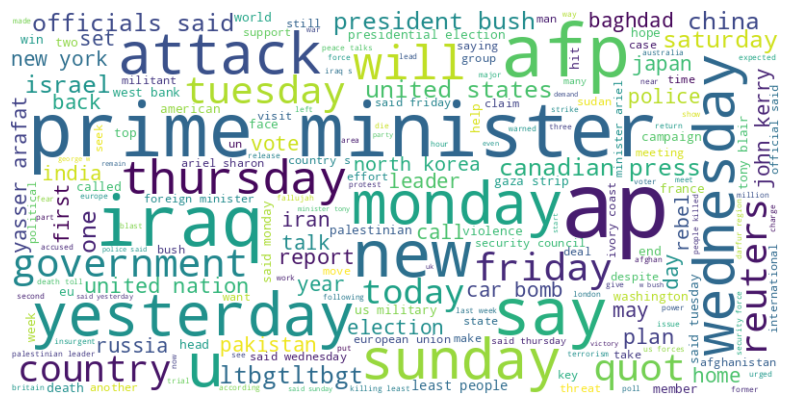

In [30]:
df = train_df[train_df['class'] == 1]
text_world_titles = clean_text(' '.join(df['title'].astype(str).tolist()))
text_world_desc = clean_text(' '.join(df['description'].astype(str).tolist()))
text_world_all = text_world_titles + ' ' + text_world_desc
generate_wordcloud(text_world_all)

In [31]:
get_top_bottom(text_world_titles, text_world_desc, text_world_all)

,Top Title,Bottom Title,Top Description,Bottom Description,Top All,Bottom All
0,new,abella,new,zoning,minister,zoroastrianism
1,ltbgtltbgt,abide,people,zonewitnesses,two,zuhua
2,bush,ability,two,zonecomplex,afp,aal
3,un,abkhaz,ap,zombie,new,aarons
4,says,quotdouble,minister,znamenskoye,president,aarshiad
5,reuters,quotexhausting,iraq,ziyang,reuters,aattacks
6,afp,abdicated,president,zircons,iraq,zumas
7,iraq,abdicating,reuters,zirconium,ap,indices
8,us,zigzags,us,abbassaid,us,indicting
9,ap,imbecile,said,abbass,said,indie


## Klasa "Sports"

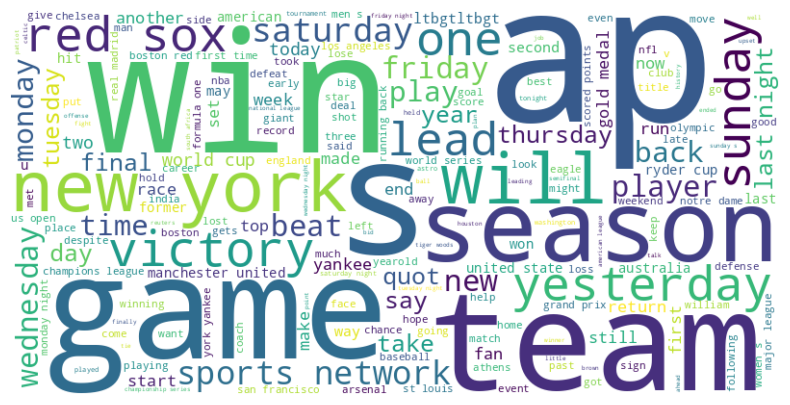

In [32]:
df = train_df[train_df['class'] == 2]
text_sports_titles = clean_text(' '.join(df['title'].astype(str).tolist()))
text_sports_desc = clean_text(' '.join(df['description'].astype(str).tolist()))
text_sports_all = text_sports_titles + ' ' + text_sports_desc
generate_wordcloud(text_sports_all)

In [33]:
get_top_bottom(text_sports_titles, text_sports_desc, text_sports_all)

,Top Title,Bottom Title,Top Description,Bottom Description,Top All,Bottom All
0,lead,abdur,world,abate,world,abdominal
1,new,abcs,last,zopyros,night,abdomen
2,sox,abbandonato,team,zorba,season,abdelmalek
3,ltbgtltbgt,abandons,season,zorilla,team,abctelevised
4,cup,abandon,night,zotinca,win,aarrett
5,us,aba,game,zoysa,will,aarons
6,wins,incomprehensible,ap,zte,game,aardsma
7,game,incompetent,will,zukauskas,first,aap
8,win,incomparable,first,ignoramus,new,aalborg
9,ap,includes,new,ignorant,ap,postapple


## Klasa "Business"

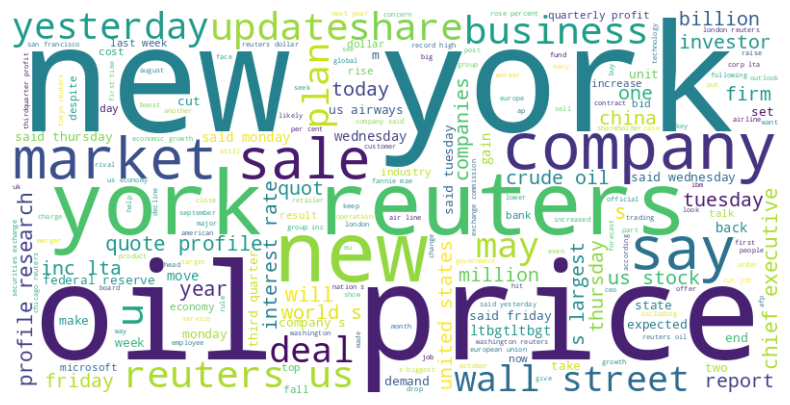

In [34]:
df = train_df[train_df['class'] == 3]
text_business_titles = clean_text(' '.join(df['title'].astype(str).tolist()))
text_business_desc = clean_text(' '.join(df['description'].astype(str).tolist()))
text_business_all = text_business_titles + ' ' + text_business_desc
generate_wordcloud(text_business_all)

In [35]:
get_top_bottom(text_business_titles, text_business_desc, text_business_all)

,Top Title,Bottom Title,Top Description,Bottom Description,Top All,Bottom All
0,deal,abil,prices,abbreviated,percent,zoos
1,new,aashare,york,abbnvx,will,zoning
2,sales,aarp,will,abbn,company,aarp
3,prices,hushed,company,abbeysantander,prices,zimbabwean
4,stocks,hurwitz,oil,abating,inc,reinvigorated
5,reuters,stereos,inc,aabn,oil,abdul
6,profit,stelzer,reuters,zyprexa,new,abdomen
7,update,stellen,new,jonescommonwealth,reuters,abcs
8,oil,hurricanestricken,us,jonescolorado,said,abcn
9,us,hyping,said,jonescoles,us,abbs


## Klasa "Sci/Tech"

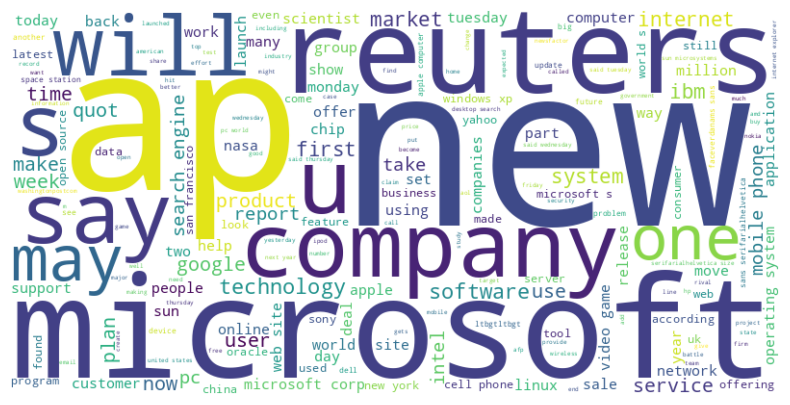

In [36]:
df = train_df[train_df['class'] == 4]
text_tech_titles = clean_text(' '.join(df['title'].astype(str).tolist()))
text_tech_desc = clean_text(' '.join(df['description'].astype(str).tolist()))
text_tech_all = text_tech_titles + ' ' + text_tech_desc
generate_wordcloud(text_tech_all)

In [37]:
get_top_bottom(text_tech_titles, text_tech_desc, text_tech_all)

,Top Title,Bottom Title,Top Description,Bottom Description,Top All,Bottom All
0,security,zingy,reuters,zope,us,theorize
1,intel,zingo,ap,zpl,company,abdul
2,space,zingers,inc,zs,internet,phishblocking
3,google,abortion,company,zseries,reuters,abdurahman
4,search,aborigines,internet,zservices,software,abe
5,ibm,aborigine,microsoft,zubi,said,abend
6,reuters,aboot,software,zubrin,ap,phished
7,ap,abolishes,said,zuckerman,will,aberdeenshire
8,new,abolish,will,zuo,microsoft,aberration
9,microsoft,abnormal,new,zvezda,new,abdoulaye


## Separowalność Klas

### Bag of Words

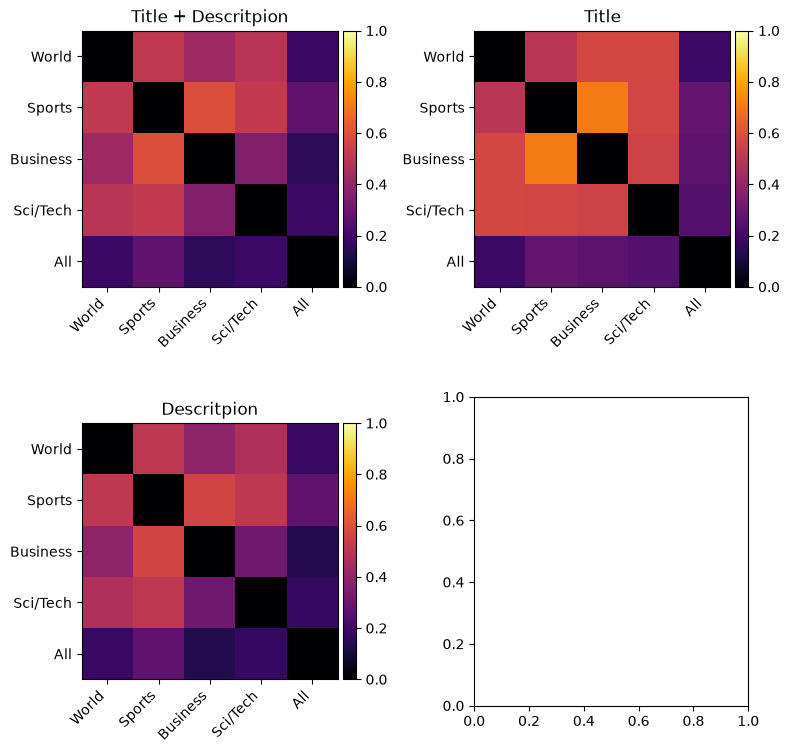

In [38]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
from sklearn.metrics import pairwise_distances


def pairwise_plot(texts, vectorizer, ax):
    labels = list(classes.values()) + ['All']
    X = vectorizer.fit_transform(texts)
    dist = pairwise_distances(X, metric='cosine')
    im = ax.imshow(dist, interpolation='none', vmin=0, vmax=1, cmap='inferno')
    ax.set_xticks(np.arange(len(labels)))
    ax.set_yticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_yticklabels(labels)

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.05)
    ax.figure.colorbar(im, cax=cax, orientation="vertical")

fig, ax = plt.subplots(2, 2, figsize=(8, 8))

ax[0][0].set_title('Title + Descritpion')
pairwise_plot(
    [text_world_all, text_sports_all, text_business_all, text_tech_all, text_all], 
    CountVectorizer(),
    ax[0][0]
)

ax[0][1].set_title('Title')
pairwise_plot(
    [text_world_titles, text_sports_titles, text_business_titles, text_tech_titles, text_titles], 
    CountVectorizer(),
    ax[0][1]
)

ax[1][0].set_title('Descritpion')
pairwise_plot(
    [text_world_desc, text_sports_desc, text_business_desc, text_tech_desc, text_desc], 
    CountVectorizer(),
    ax[1][0]
)

fig.tight_layout()
plt.show()

### Binary Bag of Words

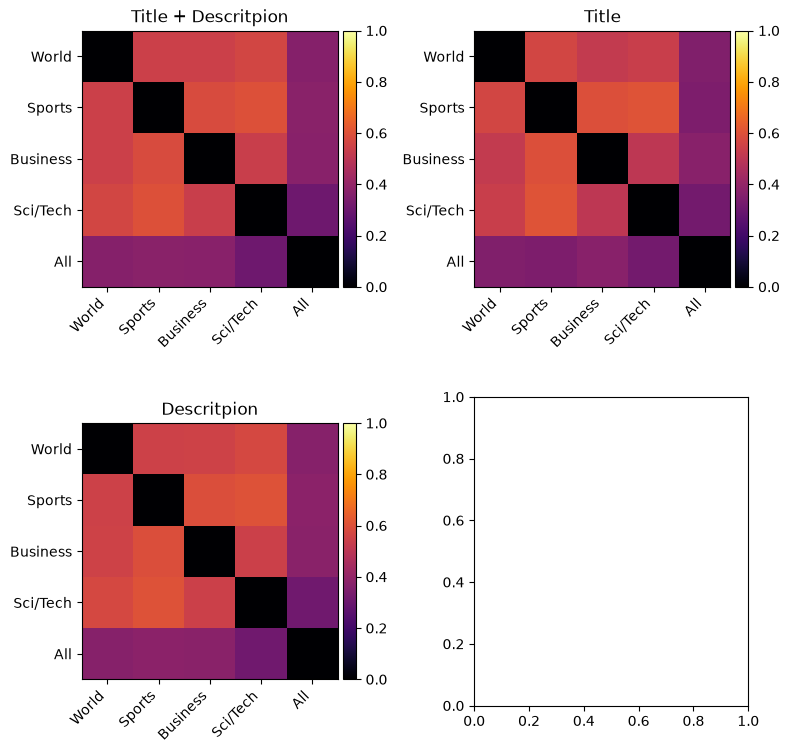

In [39]:
fig, ax = plt.subplots(2, 2, figsize=(8, 8))

ax[0][0].set_title('Title + Descritpion')
pairwise_plot(
    [text_world_all, text_sports_all, text_business_all, text_tech_all, text_all], 
    CountVectorizer(binary=True),
    ax[0][0]
)

ax[0][1].set_title('Title')
pairwise_plot(
    [text_world_titles, text_sports_titles, text_business_titles, text_tech_titles, text_titles], 
    CountVectorizer(binary=True),
    ax[0][1]
)

ax[1][0].set_title('Descritpion')
pairwise_plot(
    [text_world_desc, text_sports_desc, text_business_desc, text_tech_desc, text_desc], 
    CountVectorizer(binary=True),
    ax[1][0]
)

fig.tight_layout()
plt.show()

### Tf-Idf

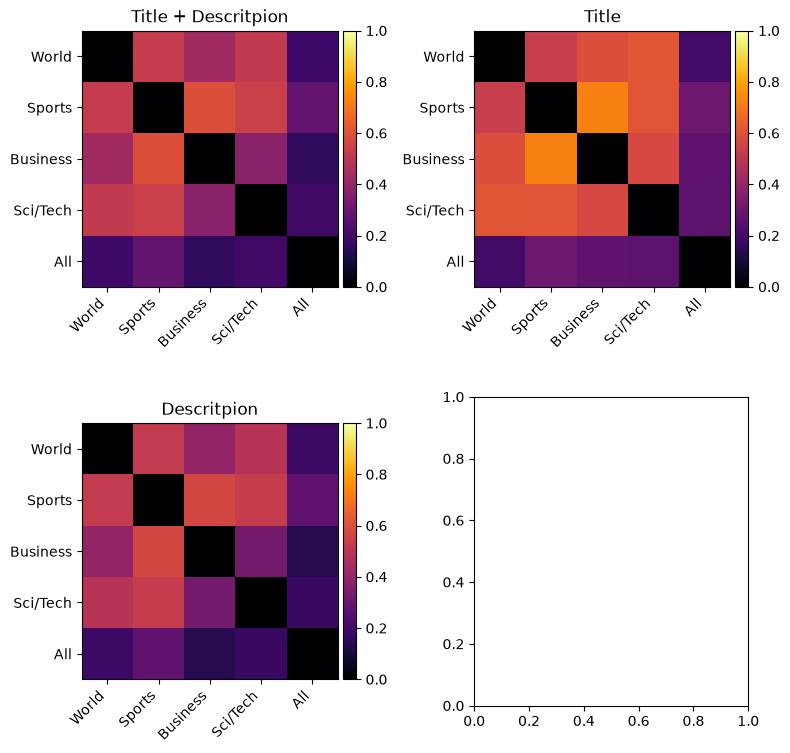

In [40]:
from sklearn.feature_extraction.text import TfidfVectorizer

fig, ax = plt.subplots(2, 2, figsize=(8, 8))

ax[0][0].set_title('Title + Descritpion')
pairwise_plot(
    [text_world_all, text_sports_all, text_business_all, text_tech_all, text_all], 
    TfidfVectorizer(),
    ax[0][0]
)

ax[0][1].set_title('Title')
pairwise_plot(
    [text_world_titles, text_sports_titles, text_business_titles, text_tech_titles, text_titles], 
    TfidfVectorizer(),
    ax[0][1]
)

ax[1][0].set_title('Descritpion')
pairwise_plot(
    [text_world_desc, text_sports_desc, text_business_desc, text_tech_desc, text_desc], 
    TfidfVectorizer(),
    ax[1][0]
)

fig.tight_layout()
plt.show()

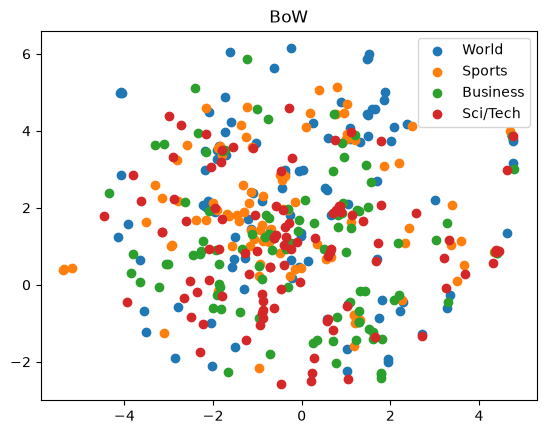

In [41]:
from sklearn.manifold import TSNE

small_df = pd.concat([
    train_df[train_df['class'] == 1].sample(100, random_state=1),
    train_df[train_df['class'] == 2].sample(100, random_state=1),
    train_df[train_df['class'] == 3].sample(100, random_state=1),
    train_df[train_df['class'] == 4].sample(100, random_state=1),
])

vectorizer = CountVectorizer()
X = vectorizer.fit_transform(small_df['title'])
X_embedded = TSNE(n_components=2).fit_transform(X)

for c, c_name in classes.items():
    x = X_embedded[small_df['class'] == c, 0]
    y = X_embedded[small_df['class'] == c, 1]
    plt.scatter(x, y, label=c_name)
plt.title('BoW')
plt.legend()

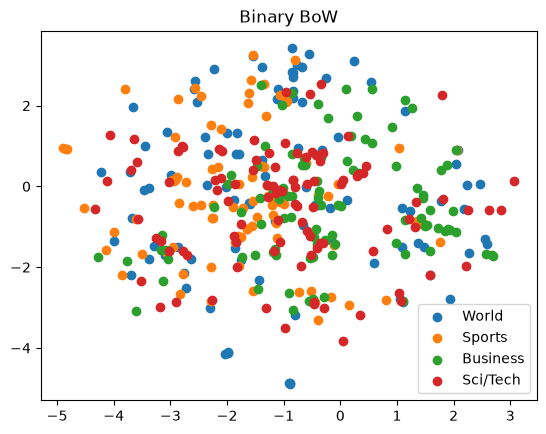

In [42]:
vectorizer = CountVectorizer(binary=True)
X = vectorizer.fit_transform(small_df['title'])
X_embedded = TSNE(n_components=2).fit_transform(X)

for c, c_name in classes.items():
    x = X_embedded[small_df['class'] == c, 0]
    y = X_embedded[small_df['class'] == c, 1]
    plt.scatter(x, y, label=c_name)
plt.title('Binary BoW')
plt.legend()

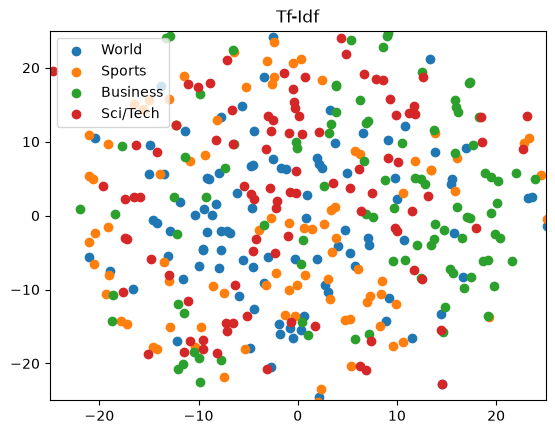

In [43]:
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(small_df['title'])
X_embedded = TSNE(n_components=2).fit_transform(X)

for c, c_name in classes.items():
    x = X_embedded[small_df['class'] == c, 0]
    y = X_embedded[small_df['class'] == c, 1]
    plt.scatter(x, y, label=c_name)
plt.title('Tf-Idf')
plt.xlim(-25, 25)
plt.ylim(-25, 25)
plt.legend()

## Artefakty

In [44]:
from collections import Counter

import nltk
from nltk.corpus import gutenberg

nltk.download('gutenberg')
words = {str(word).lower() for word in gutenberg.words()}

Counter(word for word in text_all.split(' ') if word not in words)

[nltk_data] Downloading package gutenberg to
[nltk_data]     C:\Users\marce\AppData\Roaming\nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!


Counter({'reuters': 17243,
         'ap': 16148,
         'inc': 6537,
         'iraq': 5886,
         'microsoft': 5585,
         'corp': 4821,
         'afp': 4522,
         'percent': 4482,
         'quot': 4402,
         'internet': 3865,
         'technology': 2874,
         'ltbgtltbgt': 2559,
         'iraqi': 2478,
         'update': 2430,
         'google': 2421,
         'ibm': 2399,
         'baghdad': 2214,
         'wireless': 2081,
         'lta': 2032,
         'nuclear': 1997,
         'phone': 1958,
         'palestinian': 1902,
         'sox': 1870,
         'olympic': 1800,
         'global': 1779,
         'israeli': 1771,
         'intel': 1737,
         'investors': 1720,
         'iran': 1602,
         'eu': 1534,
         'peoplesoft': 1511,
         'uk': 1509,
         'pakistan': 1496,
         'video': 1495,
         'pc': 1479,
         'championship': 1429,
         'linux': 1377,
         'tokyo': 1362,
         'digital': 1337,
         'nasa': 1332,
   

Cel biznesowy:
Klasyfikator wiadomości na platformie typu agregator wiadomości (dobór reklam, sugerowanie innych artykułow, tworzenie zbiorczych zestawień tematycznych).

Hipotezy:
- Usunięcie artefaktów HTML poprawi klasyfikację wiadomości
- Usunięcie stopwordów poprawi klasyfikację wiadomości
- Same tytuły będą dawały lepsze wyniki w prostych metodach niż połączenie tytułów i opisów
- Tf-Idf będzie skuteczny w separacji klas